In [ ]:
#구글 드라이브 마운트 하기
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

[도형의 갯수] Contour:12


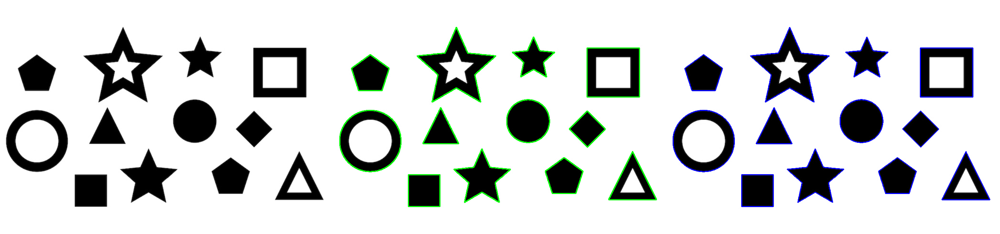

In [1]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow


srcimg = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/shapes.jpg')
#srcimg = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/shapes/shapes_inv.jpg')

img1 = srcimg.copy()
img2 = srcimg.copy()

grayimg = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
ret, imthres = cv2.threshold(grayimg, 127, 255, cv2.THRESH_BINARY_INV)


# 가장 바깥쪽 컨투어에 대해 파이썬 리스트 형태로 모든 좌표 반환: cv2.CHAIN_APPROX_NONE
contour, hierarchy = cv2.findContours(imthres, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
cv2.drawContours(img1, contour, -1, (0,255,0), 2)


# 컨투어 모든 좌표를 파랑색 원으로 그리기
for i in contour:
    for j in i:
        cv2.circle(img2, tuple(j[0]), 1, (255,0,0), -1)


# 각각의 컨투의 갯수 출력
print('[도형의 갯수] Contour:%d'% (len(contour)))

image_frame = np.hstack([srcimg,img1,img2])
cv2_imshow(image_frame)

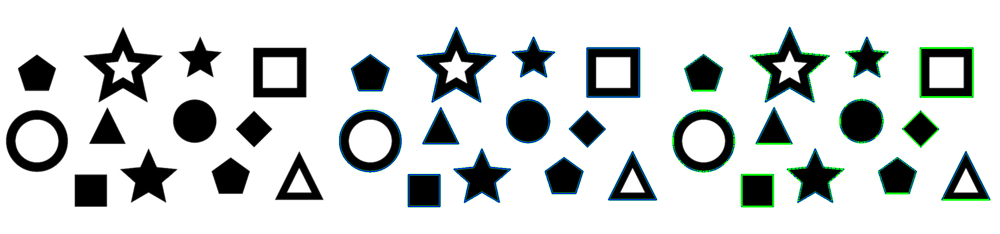

In [2]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow


srcimg = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/shapes.jpg')
#srcimg = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/shapes/shapes_inv.jpg')
img1 = srcimg.copy()
img2 = srcimg.copy()

grayimg = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
ret, imthres = cv2.threshold(grayimg, 127, 255, cv2.THRESH_BINARY_INV)


# 가장 바깥쪽 컨투어에 대해 파이썬 리스트 형태로 모든 좌표 반환: cv2.CHAIN_APPROX_NONE
contour1, hierarchy = cv2.findContours(imthres, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
cv2.drawContours(img1, contour1, -1, (0,255,0), 4)
for i in contour1:
    for j in i:
        cv2.circle(img1, tuple(j[0]), 1, (255,0,0), -1)


# 가장 바깥쪽 컨투어에 대해 꼭지점 좌표만 반환: cv2.CHAIN_APPROX_SIMPLE
contour2, hierarchy = cv2.findContours(imthres, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cv2.drawContours(img2, contour2, -1, (0,255,0), 4)
for i in contour2:
    for j in i:
        cv2.circle(img2, tuple(j[0]), 1, (255,0,0), -1)


image_frame = np.hstack([srcimg,img1,img2])
cv2_imshow(image_frame)

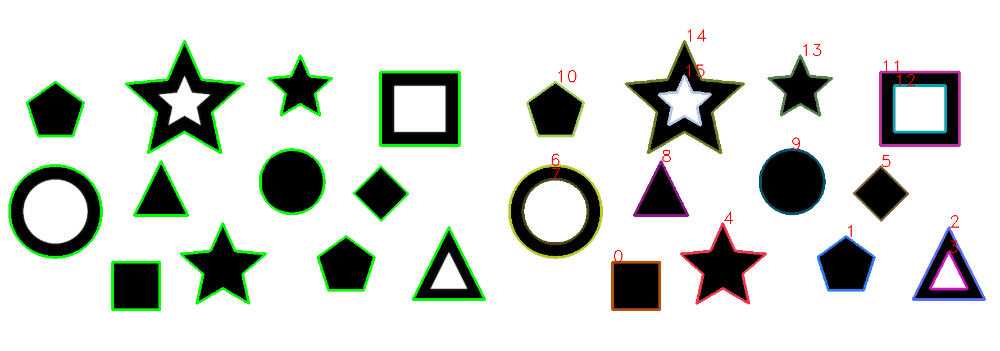

12 [Next, Prev, First Child, Parent]
[[[ 1 -1 -1 -1]
  [ 2  0 -1 -1]
  [ 3  1 -1 -1]
  [ 4  2 -1 -1]
  [ 5  3 -1 -1]
  [ 6  4 -1 -1]
  [ 7  5 -1 -1]
  [ 8  6 -1 -1]
  [ 9  7 -1 -1]
  [10  8 -1 -1]
  [11  9 -1 -1]
  [-1 10 -1 -1]]]
16 [Next, Prev, First Child, Parent]
[[[ 1 -1 -1 -1]
  [ 2  0 -1 -1]
  [ 4  1  3 -1]
  [-1 -1 -1  2]
  [ 5  2 -1 -1]
  [ 6  4 -1 -1]
  [ 8  5  7 -1]
  [-1 -1 -1  6]
  [ 9  6 -1 -1]
  [10  8 -1 -1]
  [11  9 -1 -1]
  [13 10 12 -1]
  [-1 -1 -1 11]
  [14 11 -1 -1]
  [-1 13 15 -1]
  [-1 -1 -1 14]]]


In [4]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

srcimg = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/shapes.jpg')
#srcimg = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/shapes/shapes_inv.jpg')
img1 = srcimg.copy()
img2 = srcimg.copy()

imgray = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
ret, imthres = cv2.threshold(imgray, 127, 255, cv2.THRESH_BINARY_INV)

# img1
# 가장 바깥 컨투어만 수집: cv2.RETR_EXTERNAL
contour1, hierarchy1 = cv2.findContours(imthres, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
# 가장 바깥 컨투어만 그리고 이미지 출력
cv2.drawContours(img1, contour1, -1, (0,255,0), 3)

# img2
# 모든 컨투어를 트리 계층으로 수집: cv2.RETR_TREE
contour2, hierarchy2 = cv2.findContours(imthres, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
for idx, cont in enumerate(contour2):
    # 랜덤한 컬러 추출
    color = [int(i) for i in np.random.randint(0,255, 3)]
    # 컨투어 인덱스 마다 랜덤한 색상 지정
    cv2.drawContours(img2, contour2, idx, color, 3)
    # 컨투어 첫 좌표에 인덱스 숫자 표시
    cv2.putText(img2, str(idx), tuple(cont[0][0]), cv2.FONT_HERSHEY_DUPLEX, 1, (0,0,255))

image_frame = np.hstack([img1,img2])
cv2_imshow(image_frame)

print(len(contour1),"[Next, Prev, First Child, Parent]")
print(hierarchy1)
print(len(contour2),"[Next, Prev, First Child, Parent]")
print(hierarchy2)

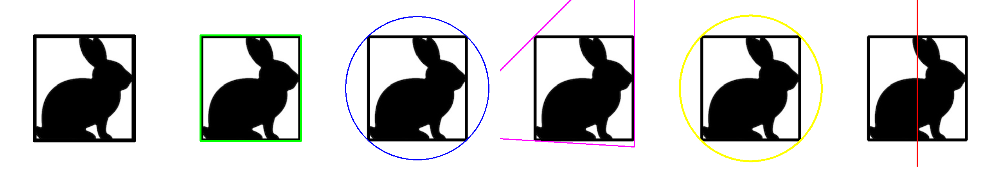

In [13]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

srcimg = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/rabbitshape.jpg')
#srcimg = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/shapes/carrotshape.jpg')
#srcimg = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/shapes/starshape.jpg')

img1 = srcimg.copy()
img2 = srcimg.copy()
img3 = srcimg.copy()
img4 = srcimg.copy()
img5 = srcimg.copy()
img6 = srcimg.copy()

imgray = cv2.cvtColor(srcimg, cv2.COLOR_BGR2GRAY)
ret, cntr_threshold = cv2.threshold(imgray, 127,255,cv2.THRESH_BINARY_INV)

# 컨투어 찾기
contours, hr = cv2.findContours(cntr_threshold, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
contour = contours[0]

# 감싸는 사각형 표시(검정색)
x,y,w,h = cv2.boundingRect(contour)
cv2.rectangle(img1, (x,y), (x+w, y+h), (0,0,0), 3)

# 최소한의 사각형 표시(초록색)
rect = cv2.minAreaRect(contour)
box = cv2.boxPoints(rect)   # 중심점과 각도를 4개의 꼭지점 좌표로 변환
box = np.intp(box)          # np.int0 대신 np.intp를 사용하여 정수로 변환
cv2.drawContours(img2, [box], -1, (0,255,0), 3)

# 최소한의 원 표시(파랑색)
(x,y), radius = cv2.minEnclosingCircle(contour)
cv2.circle(img3, (int(x), int(y)), int(radius), (255,0,0), 2)

# 최소한의 삼각형 표시(분홍색)
ret, tri = cv2.minEnclosingTriangle(contour)
cv2.polylines(img4, [np.int32(tri)], True, (255,0,255), 2)

# 최소한의 타원 표시(노랑색)
ellipse = cv2.fitEllipse(contour)
cv2.ellipse(img5, ellipse, (0,255,255), 3)

# 중심점 통과하는 직선 표시(빨강색)
[vx,vy,x,y] = cv2.fitLine(contour, cv2.DIST_L2,0,0.01,0.01)
cols,rows = img6.shape[:2]

# vx, vy, x, y 배열로부터 스칼라 값을 추출하여 계산 (.item() 사용)
vx_val = vx.item()
vy_val = vy.item()
x_val = x.item()
y_val = y.item()

# 0으로 나누기 연산 시 오버플로우 방지 처리
if abs(vx_val) < 1e-6:
    # 직선이 세로선에 수직에 가까운 경우
    y1 = 0
    y2 = rows - 1
    x1 = int(x_val)
    x2 = int(x_val)
    cv2.line(img6, (x1, y1), (x2, y2), (0, 0, 255), 2)
else:
    # 기울기를 이용해 y값 계산 후 정밀 안전 제한 범위로 clip
    y1_val = 0 - x_val * (vy_val / vx_val) + y_val
    y2_val = (cols - x_val) * (vy_val / vx_val) + y_val

    y1 = int(np.clip(y1_val, -10000, 10000))
    y2 = int(np.clip(y2_val, -10000, 10000))
    cv2.line(img6, (0, y1), (cols - 1, y2), (0, 0, 255), 2)

image_frame = np.hstack([img1,img2,img3,img4,img5,img6])
cv2_imshow(image_frame)

Index 0 area:224675
Index 1 area:88486
Index 2 area:224581
Index 3 area:177242
Index 4 area:124490


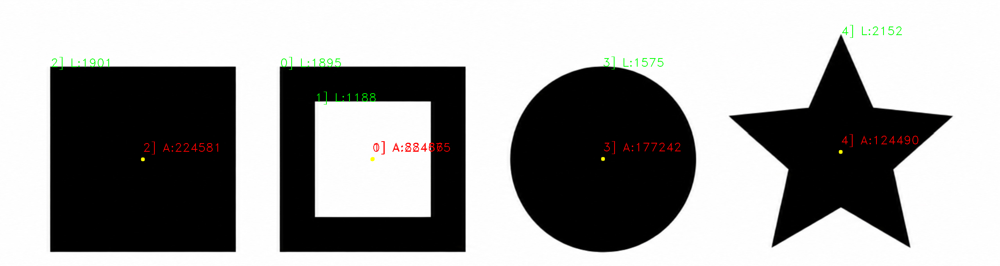

In [14]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/4shapes.jpg')
imgray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
ret, imthres = cv2.threshold(imgray, 127, 255, cv2.THRESH_BINARY_INV)
#contours, hierarchy = cv2.findContours(imthres, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
contours, hierarchy = cv2.findContours(imthres, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)

for idx, contour in enumerate(contours):
  moment = cv2.moments(contour)
  #중심점 찾기
  cx = int(moment['m10']/moment['m00'])
  cy = int(moment['m01']/moment['m00'])
  #영역 넓이
  area = moment['m00']
  length = cv2.arcLength(contour,True)
  cv2.circle(img,(cx,cy),5,(0,255,255),-1)
  cv2.putText(img,"{}] L:{:.0f}".format(idx,length), tuple(contour[0][0]), cv2.FONT_HERSHEY_DUPLEX,1,(0,255,0))

  #종속관계 확인 후 넓이와 둘레길이 표기
  pIdx = hierarchy[0][idx][3]
  pMoment = cv2.moments(contours[pIdx])
  pcy = int(pMoment['m01']/pMoment['m00'])

  if (pIdx != -1) and (pcy == cy):
    cv2.putText(img,"{}] A:{:.0f}".format(idx,area),(cx,cy+20), cv2.FONT_HERSHEY_DUPLEX,1,(0,0,255))
  else:
    cv2.putText(img,"{}] A:{:.0f}".format(idx,area),(cx,cy-20), cv2.FONT_HERSHEY_DUPLEX,1,(0,0,255))

  print("Index {} area:{:.0f}".format(idx, cv2.contourArea(contour)))


cv2_imshow(img)

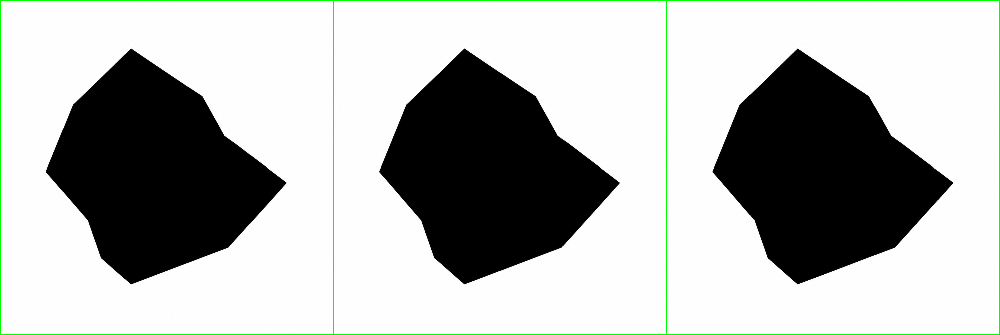

In [16]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img1 = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/randomshape.jpg')
img2 = img1.copy()
img3 = img1.copy()

# 그레이스케일과 바이너리 스케일 변환
imgray = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
ret, th = cv2.threshold(imgray, 127, 255, cv2.THRESH_BINARY)

# 컨투어 찾기
contours, hierachy = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
contour = contours[0]

# 전체 둘레의 0.05로 오차 범위 지정
epsilon1 = 0.05 * cv2.arcLength(contour, True)
approx1 = cv2.approxPolyDP(contour, epsilon1, True)

# 전체 둘레의 0.09로 오차 범위 지정
epsilon2 = 0.09 * cv2.arcLength(contour, True)
approx2 = cv2.approxPolyDP(contour, epsilon2, True)


# 각각 컨투어 선 그리기
cv2.drawContours(img1, [contour], -1, (0,255,0), 3)
cv2.drawContours(img2, [approx1], -1, (0,255,0), 3)
cv2.drawContours(img3, [approx2], -1, (0,255,0), 3)

image_frame = np.hstack([img1,img2,img3])
cv2_imshow(image_frame)


False True


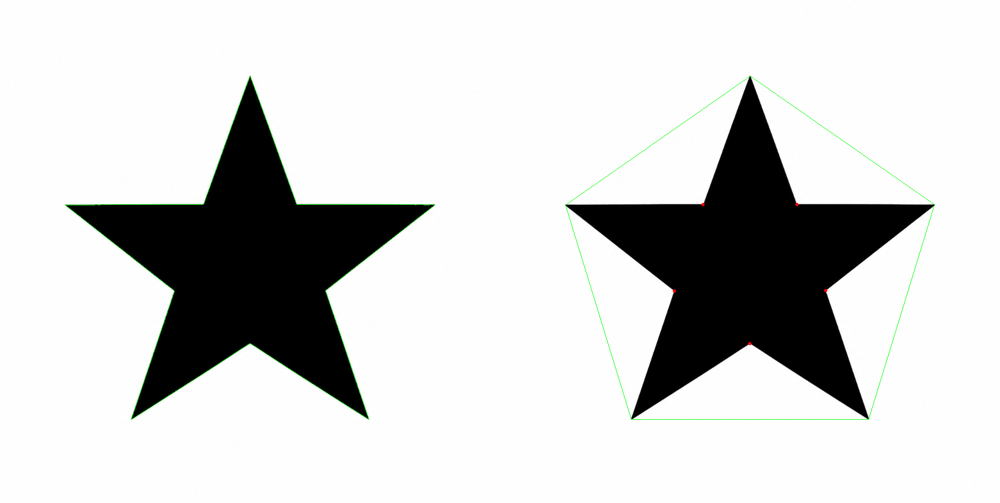

In [17]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img1 = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/starshape.jpg')
#img1 = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/shapes/rabbitshape.jpg')
#img1 = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/shapes/carrotshape.jpg')
img2 = img1.copy()

gray = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
ret, th = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY_INV)
contours, heiarchy = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

cntr = contours[0]
cv2.drawContours(img1, [cntr], -1, (0, 255,0), 1)

# 볼록 선체 찾기(좌표 기준)와 그리기
hull = cv2.convexHull(cntr)
cv2.drawContours(img2, [hull], -1, (0,255,0), 1)
# 볼록 선체 만족 여부 확인
print(cv2.isContourConvex(cntr), cv2.isContourConvex(hull))

# 볼록 선체 찾기(인덱스 기준)
hull2 = cv2.convexHull(cntr, returnPoints=False)
# 볼록 선체 결함 찾기
defects = cv2.convexityDefects(cntr, hull2)
# 볼록 선체 결함 순회
for i in range(defects.shape[0]):
    # 시작, 종료, 가장 먼 지점, 거리
    startP, endP, farthestP, distance = defects[i, 0]
    # 가장 먼 지점의 좌표 구하기
    farthest = tuple(cntr[farthestP][0])
    # 거리를 부동 소수점으로 변환
    dist = distance/256.0
    # 거리가 1보다 큰 경우
    if dist > 1 :
        # 빨강색 점 표시
        cv2.circle(img2, farthest, 3, (0,0,255), -1)

image_frame = np.hstack([img1,img2])
cv2_imshow(image_frame)


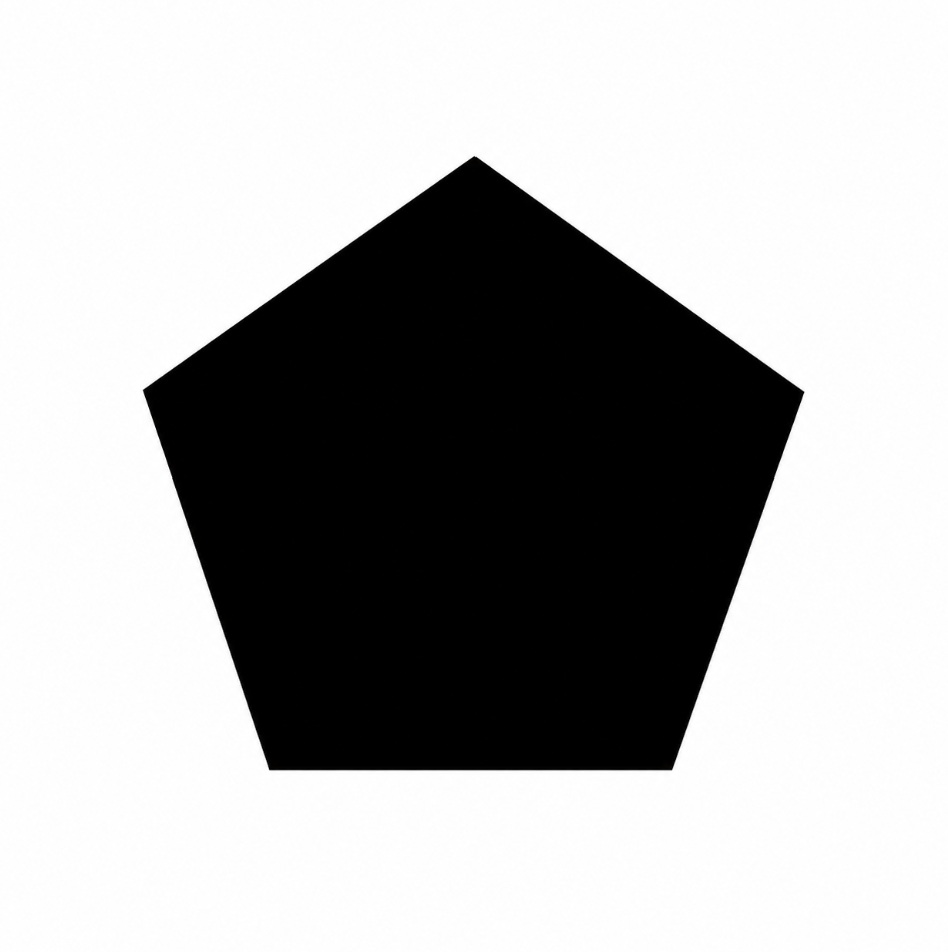

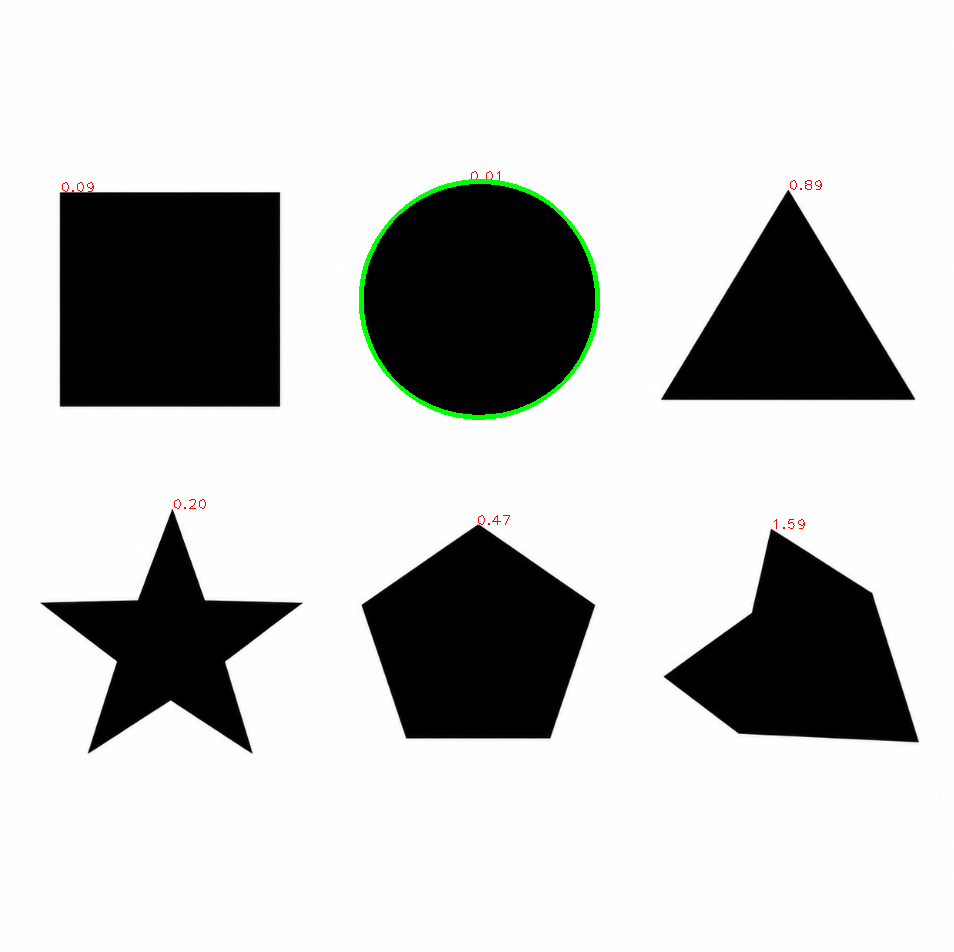

In [15]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow


# 매칭을 위한 이미지 읽기
#target = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/circleshape.jpg') # 매칭 대상
#target = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/starshape.jpg') # 매칭 대상
target = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/pentashape.jpg') # 매칭 대상

shapes = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/shapes.jpg') # 여러 도형


targetGray = cv2.cvtColor(target, cv2.COLOR_BGR2GRAY)
shapesGray = cv2.cvtColor(shapes, cv2.COLOR_BGR2GRAY)

ret, targetTh = cv2.threshold(targetGray, 127, 255, cv2.THRESH_BINARY_INV)
ret, shapesTh = cv2.threshold(shapesGray, 127, 255, cv2.THRESH_BINARY_INV)


cntrs_target, _ = cv2.findContours(targetTh, cv2.RETR_EXTERNAL, \
                                            cv2.CHAIN_APPROX_SIMPLE)
cntrs_shapes, _ = cv2.findContours(shapesTh, cv2.RETR_EXTERNAL, \
                                            cv2.CHAIN_APPROX_SIMPLE)


matchs = [] # 컨투어와 매칭 점수를 보관할 리스트
for contr in cntrs_shapes:
    # 대상 도형과 여러 도형 중 하나와 매칭 실행
    match = cv2.matchShapes(cntrs_target[0], contr, cv2.CONTOURS_MATCH_I2, 0.0)
    # 해당 도형의 매칭 점수와 컨투어를 쌍으로 저장
    matchs.append( (match, contr) )
    # 해당 도형의 컨투어 시작지점에 매칭 점수 표시
    cv2.putText(shapes, '%.2f'%match, tuple(contr[0][0]), cv2.FONT_HERSHEY_PLAIN, 1,(0,0,255),1 )

# 매칭 점수로 정렬
matchs.sort(key=lambda x : x[0])
# 가장 적은 매칭 점수를 얻는 도형의 컨투어에 선 그리기
cv2.drawContours(shapes, [matchs[0][1]], -1, (0,255,0), 3)
cv2_imshow(target)
cv2_imshow(shapes)

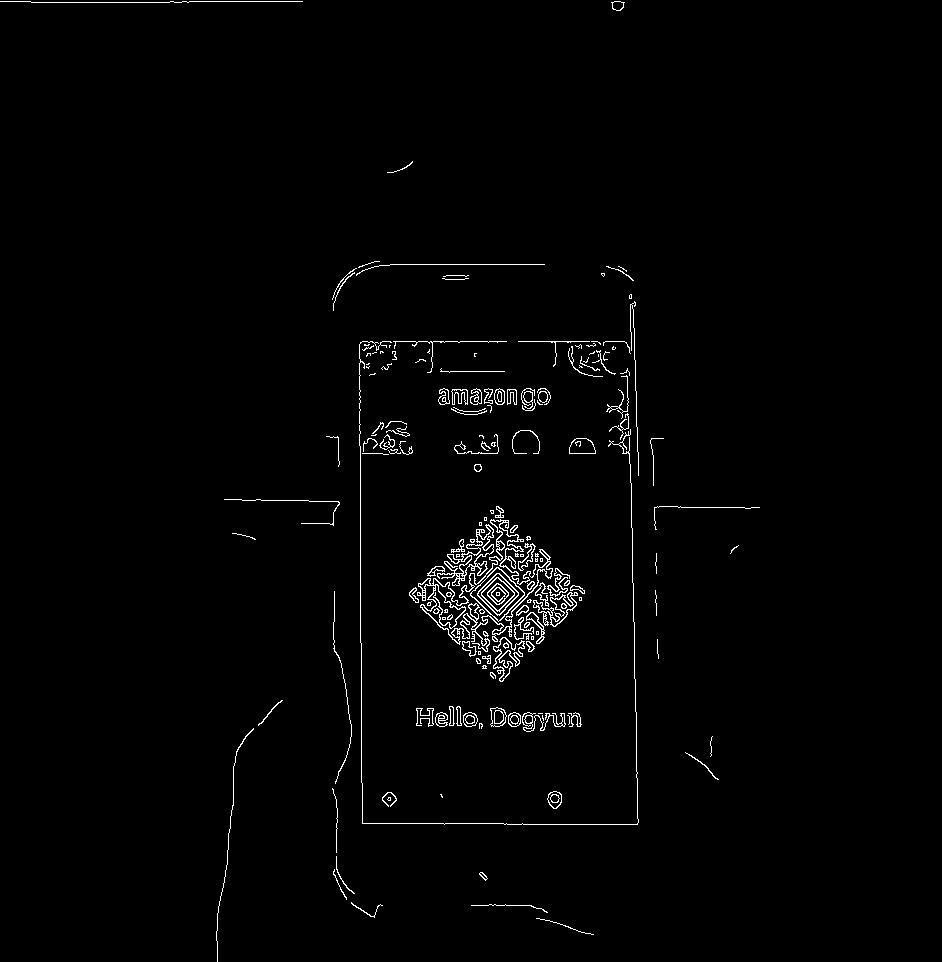

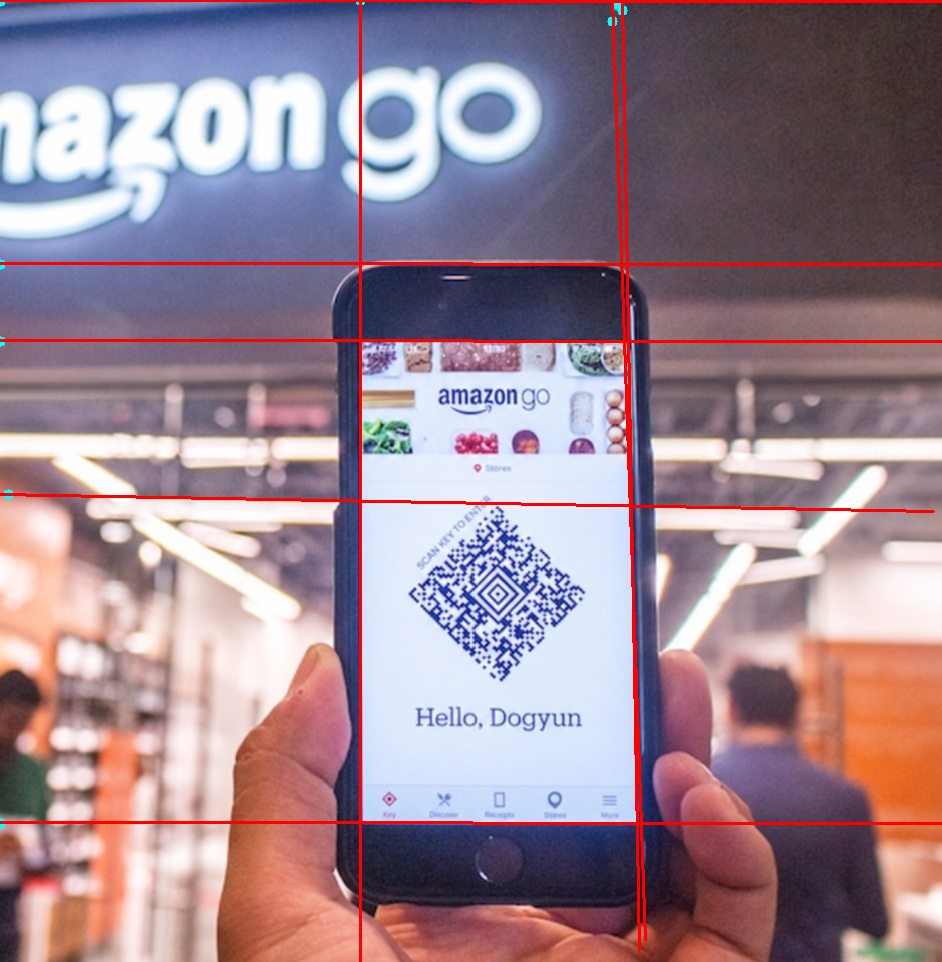

In [20]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow


img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/QRcellphone.jpg')

img2 = img.copy()

height, width = img.shape[:2]

imgray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
edges = cv2.Canny(imgray, 250, 400)
cv2_imshow(edges)

# 허프 선 검출, 직선으로 판단할 최소한의 점은 130개로 지정
lines = cv2.HoughLines(edges, 1, np.pi/180, 130)

for line in lines: # 검출된 모든 선
  for rho, theta in line:
    tx, ty = np.cos(theta), np.sin(theta) # x,y축에 대한 삼각비
    x0, y0 = tx*rho, ty*rho  #x, y 기준(절편) 좌표

    # 정수형(int)으로 캐스팅하여 OpenCV 에러 해결
    cv2.circle(img2, (int(abs(x0)), int(abs(y0))), 5, (255,255,0), -1)

    # 직선 방정식으로 그리기 위한 시작점, 끝점 계산
    x1, y1 = int(x0 + width*(-ty)), int(y0 + height * tx)
    x2, y2 = int(x0 - width*(-ty)), int(y0 - height * tx)

    # 선그리기
    cv2.line(img2, (x1, y1), (x2, y2), (0,0,255), 2)

cv2_imshow(img2)

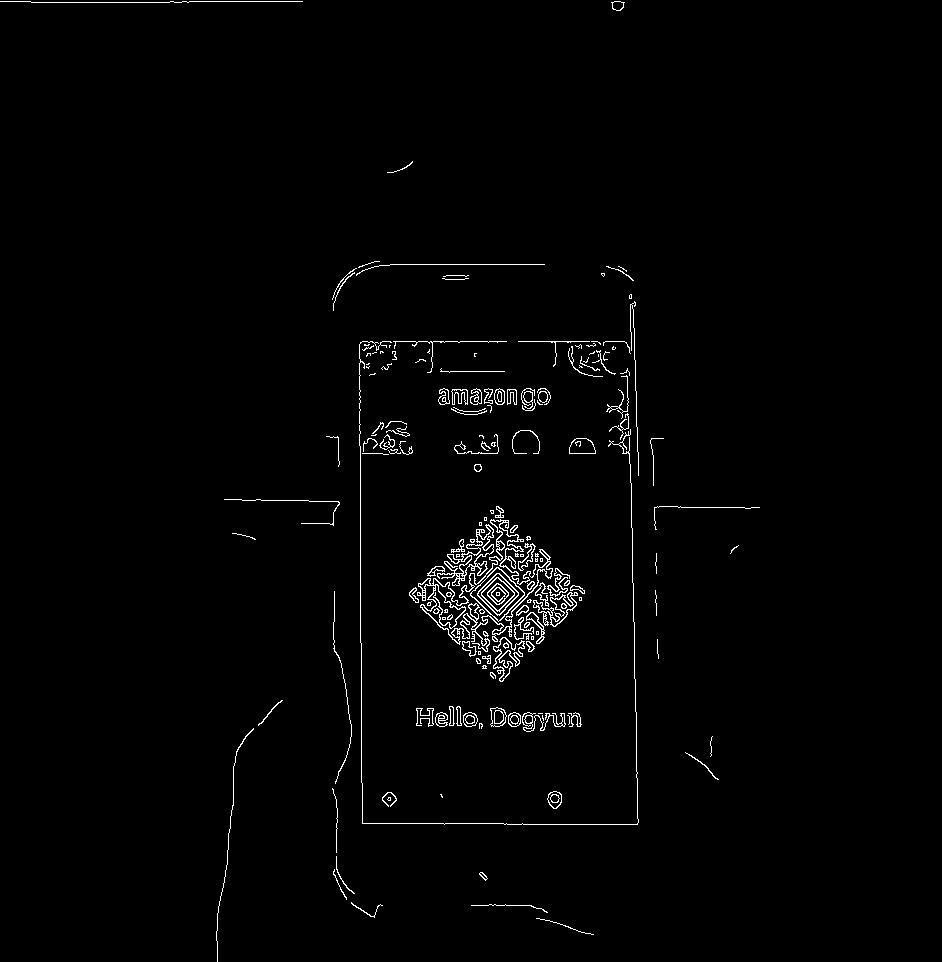

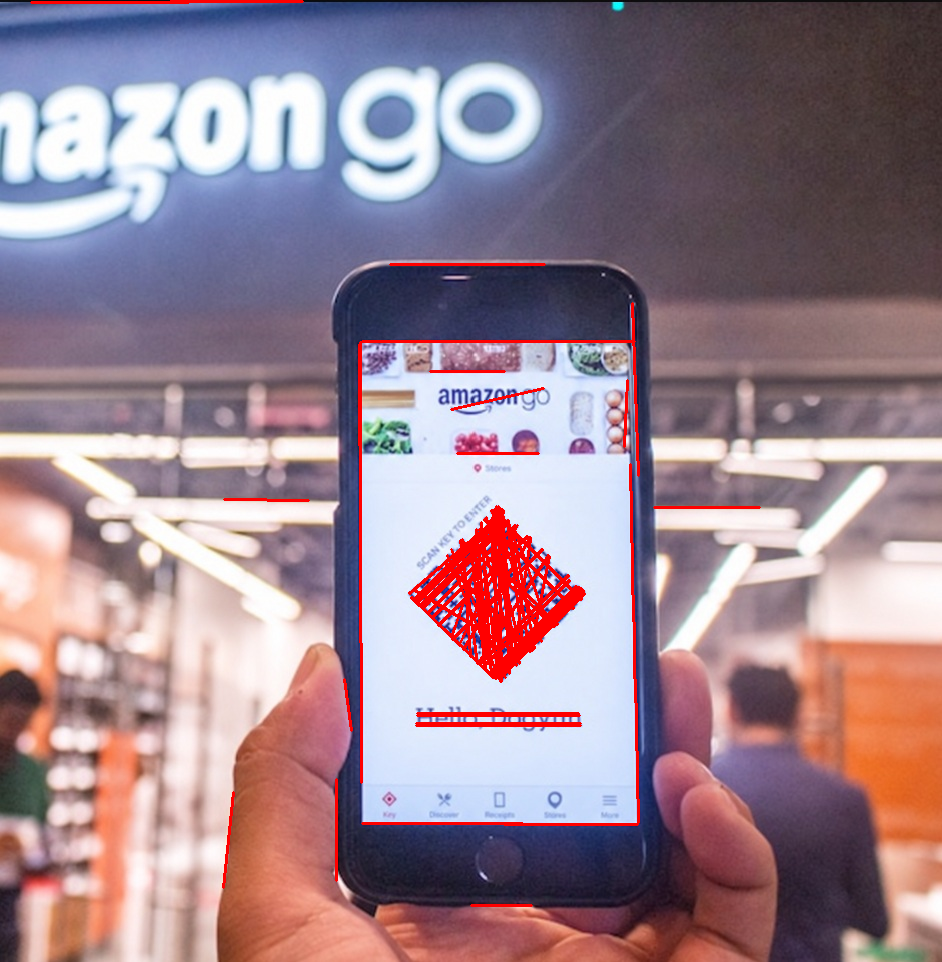

In [21]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/QRcellphone.jpg')
img2 = img.copy()

# 그레이 스케일로 변환 및 캐니 엣지 검출
imgray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
edges = cv2.Canny(imgray, 250, 400)
cv2_imshow(edges)

rho = 1
theta = np.pi/180
threshold = 60
min_line_length = 50
max_line_gap = 20


# 확율 허프 변환 적용
lines = cv2.HoughLinesP(edges, rho, theta, threshold, None, min_line_length, max_line_gap)

for line in lines:
    # 검출된 선 그리기
    for x1,y1,x2,y2 in line:
        cv2.line(img2,(x1,y1),(x2,y2),(0,0,255),2)

cv2_imshow(img2)

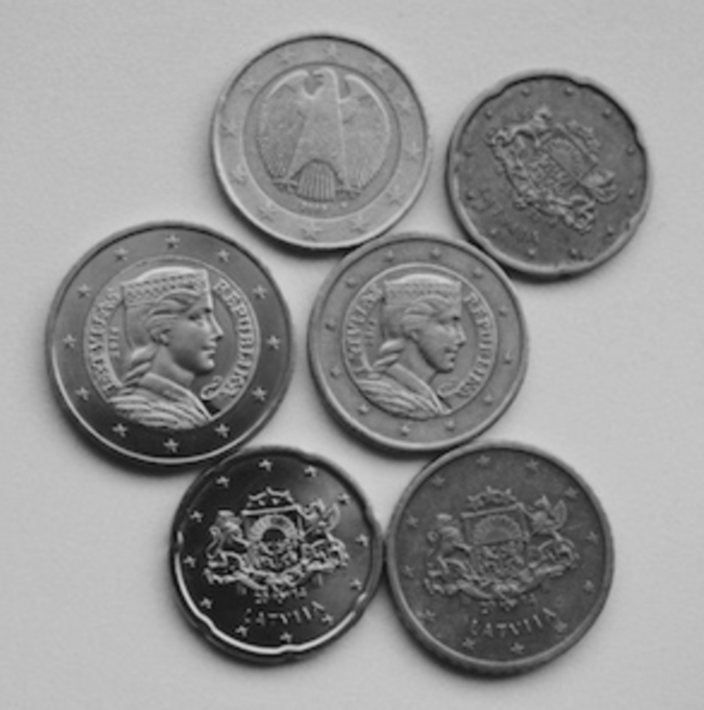

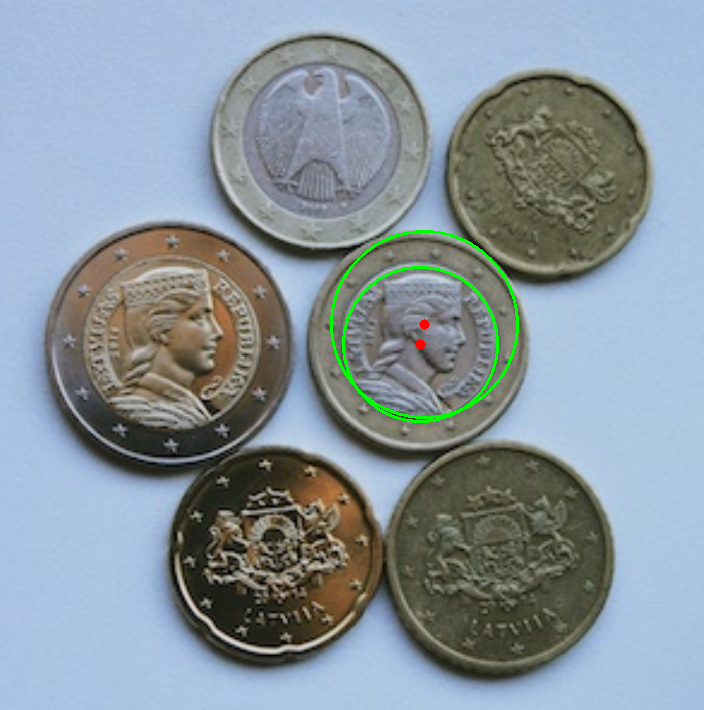

In [32]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

#img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/coins600x300.jpg')
img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/coins300x300.jpg')

# 노이즈 제거를 위한 가우시안 블러
blurimg = cv2.GaussianBlur(gray, (3,3), 0)
cv2_imshow(blurimg)

dp = 1
minDist = 20

circles = cv2.HoughCircles(blurimg, cv2.HOUGH_GRADIENT, dp, minDist, minRadius=10, maxRadius=100)
if circles is not None:
    circles = np.uint16(np.around(circles))
    for i in circles[0,:]:
        # 원 둘레에 초록색 원 그리기
        cv2.circle(img,(i[0], i[1]), i[2], (0, 255, 0), 2)
        # 원 중심점에 빨강색 원 그리기
        cv2.circle(img, (i[0], i[1]), 2, (0,0,255), 6)

# 결과 출력
cv2_imshow(img)

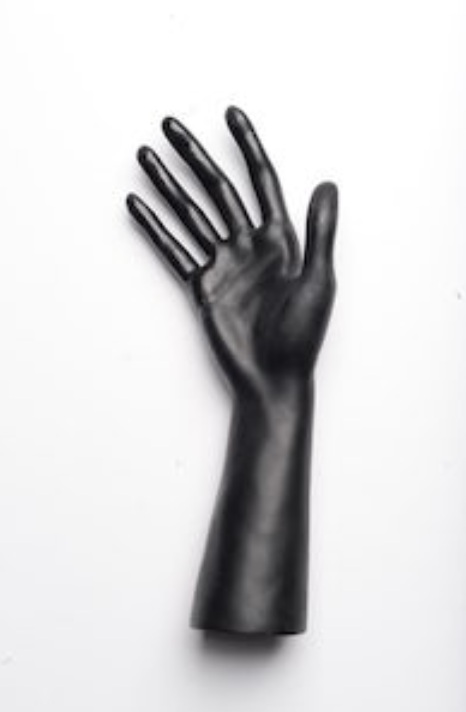

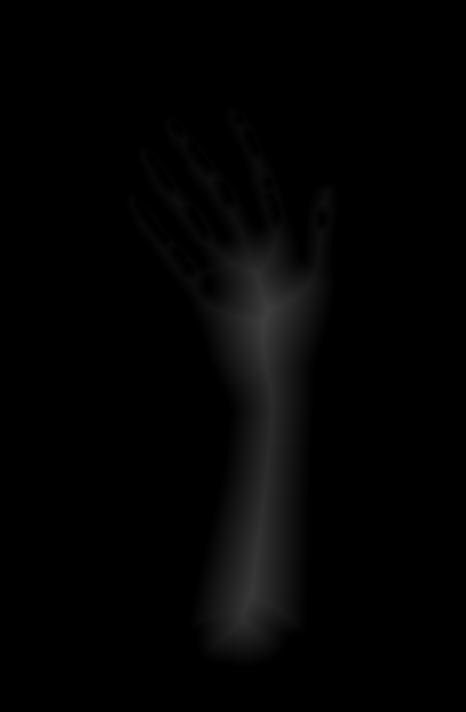

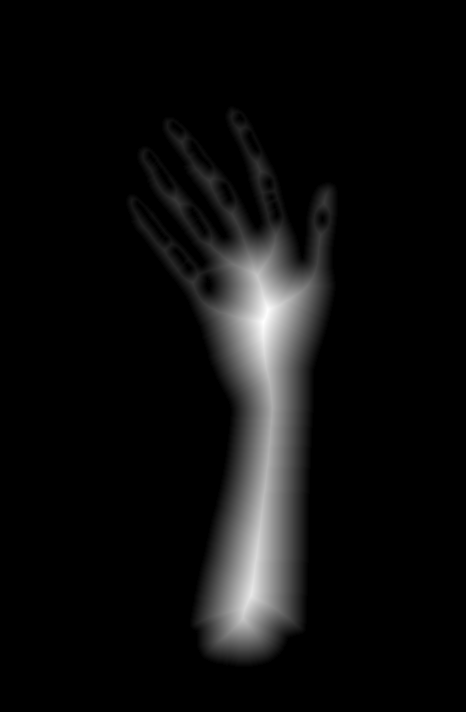

In [26]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

#img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/shapes/4shapes.jpg')
img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/hand.jpg')

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
ret, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

dist_transform = cv2.distanceTransform(thresh, cv2.DIST_L2, 5)

# dist_transform 함수를 사용하면 실수 타입(float32)의 이미지가 생성
#normalize 함수를 사용
result = cv2.normalize(dist_transform, None, 255, 0, cv2.NORM_MINMAX, cv2.CV_8UC1)

cv2_imshow(img)
cv2_imshow(dist_transform)
cv2_imshow(result)

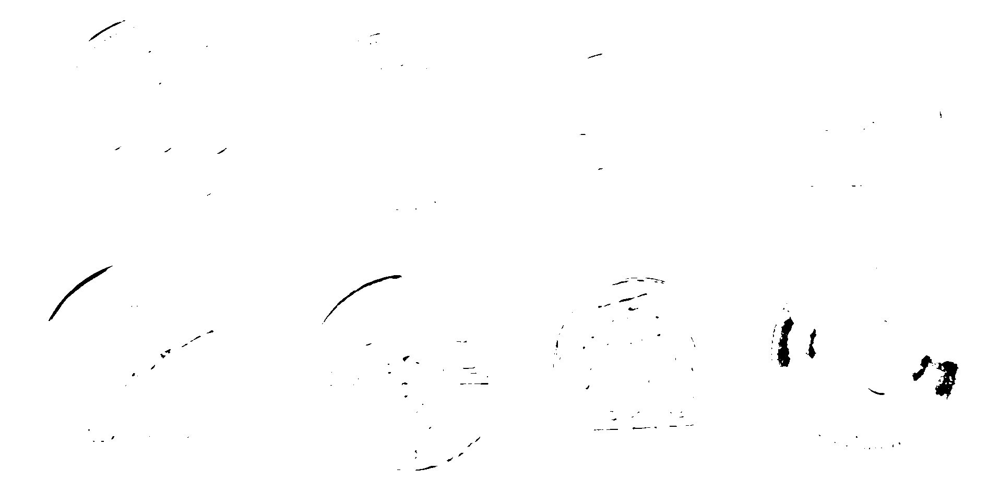

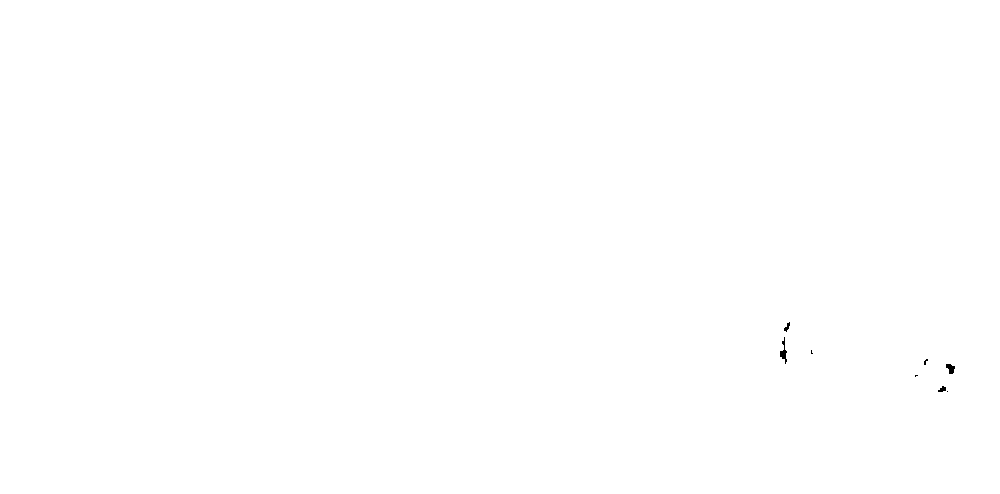

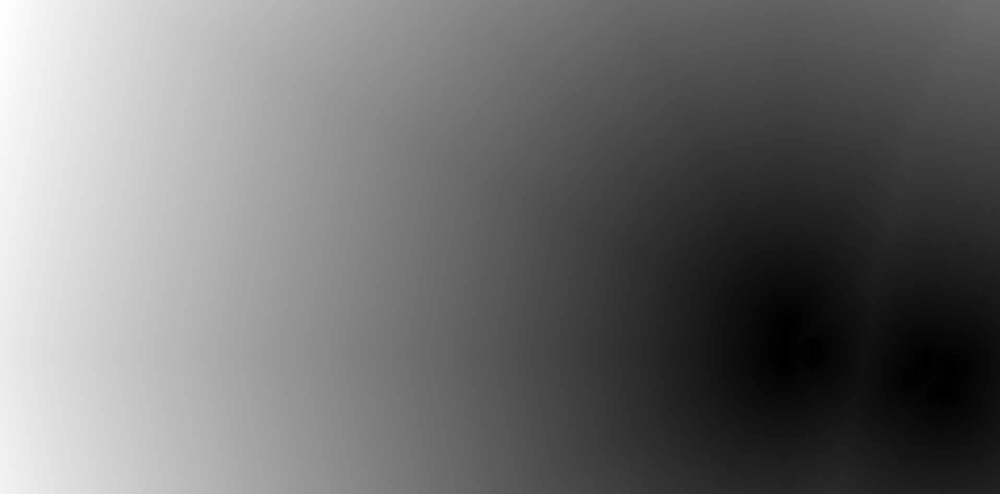

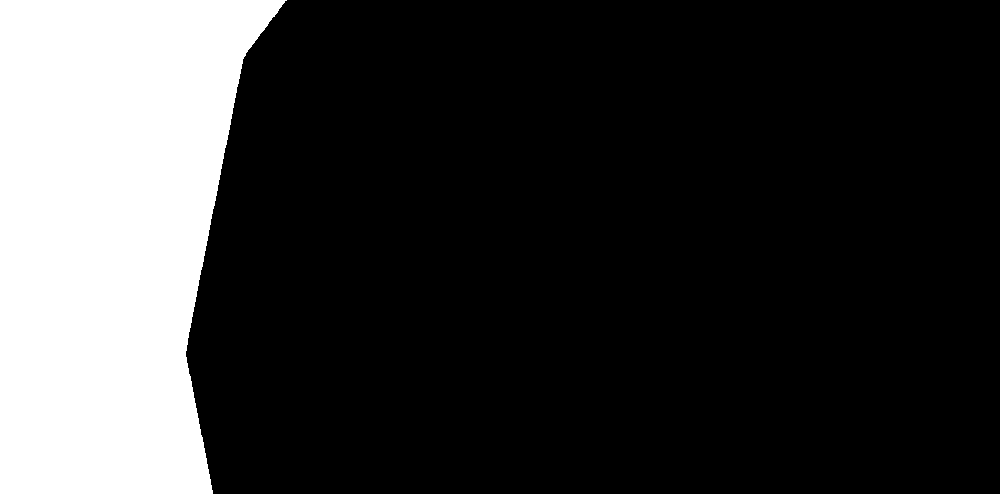

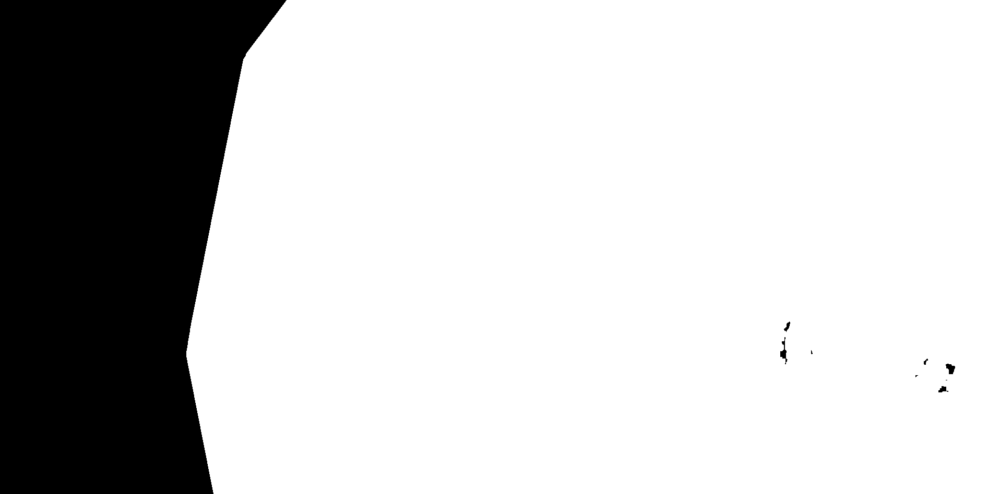

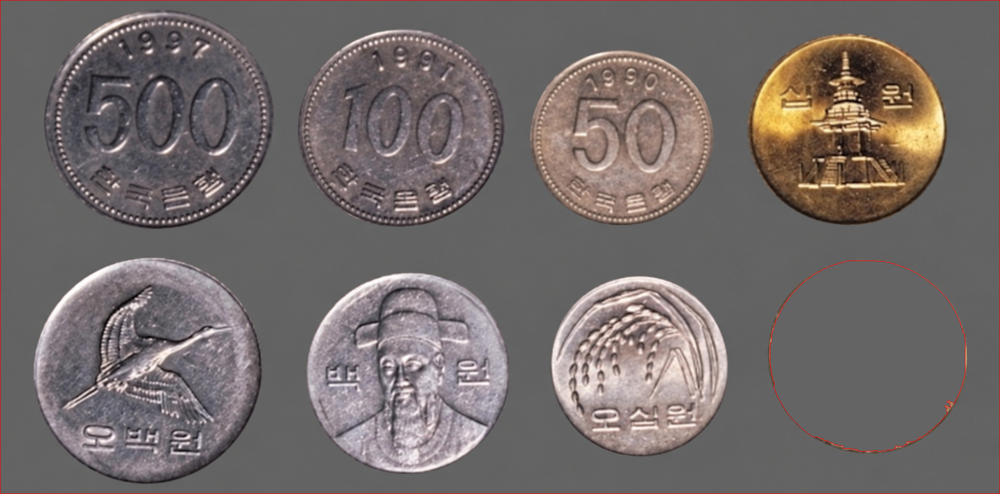

In [29]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/coins600x300.jpg')

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
ret, thresh = cv2.threshold(gray,240,255,cv2.THRESH_BINARY_INV)
cv2_imshow(thresh)


#모폴로지를 사용해 노이즈나 구멍제거
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (9,9))
sure_bg = cv2.dilate(thresh, kernel)
cv2_imshow(sure_bg)

#동전 중앙 부분을 검출하기 위해서 distance transform를 적용
dist_transform = cv2.distanceTransform(sure_bg, cv2.DIST_L2, 5)
result_dist_transform = cv2.normalize(dist_transform, None, 255, 0, cv2.NORM_MINMAX, cv2.CV_8UC1)
cv2_imshow(result_dist_transform)
# 이진화 스레시홀딩 적용
ret, sure_fg = cv2.threshold(dist_transform, 0.7*dist_transform.max(),255, cv2.THRESH_BINARY)
cv2_imshow(sure_fg)

sure_fg = np.uint8(sure_fg)
unknown = cv2.subtract(sure_bg,sure_fg)
cv2_imshow(unknown)

# 마커 라벨링
ret, markers = cv2.connectedComponents(sure_fg)

# 확실한 배경이 1이 되도록 모든 라벨에 1을 더함
markers = markers+1

# 확실하지 않은 구간을 0으로 처리
markers[unknown==255] = 0

markers = cv2.watershed(img, markers)

img[markers == -1] = [0, 0, 255]
img[markers == 1] = [100, 100, 100]

cv2_imshow(img)

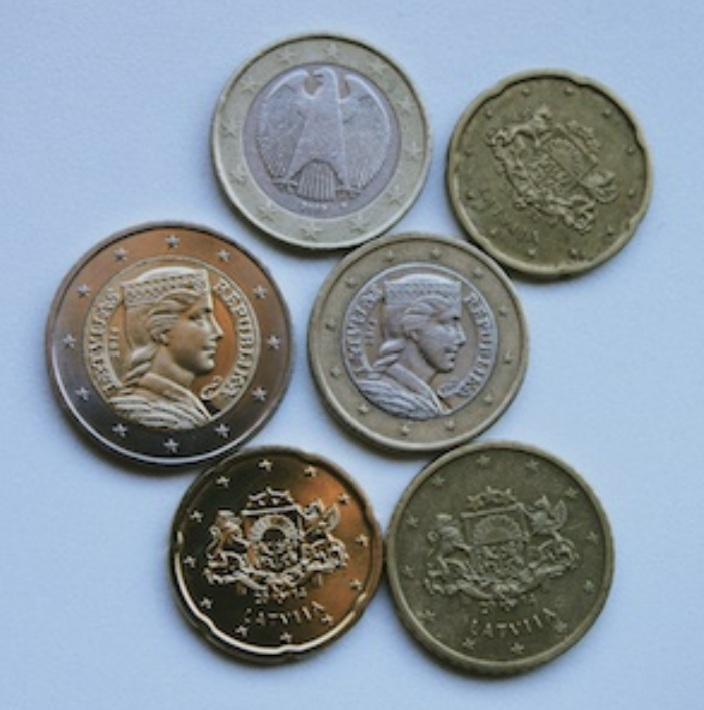

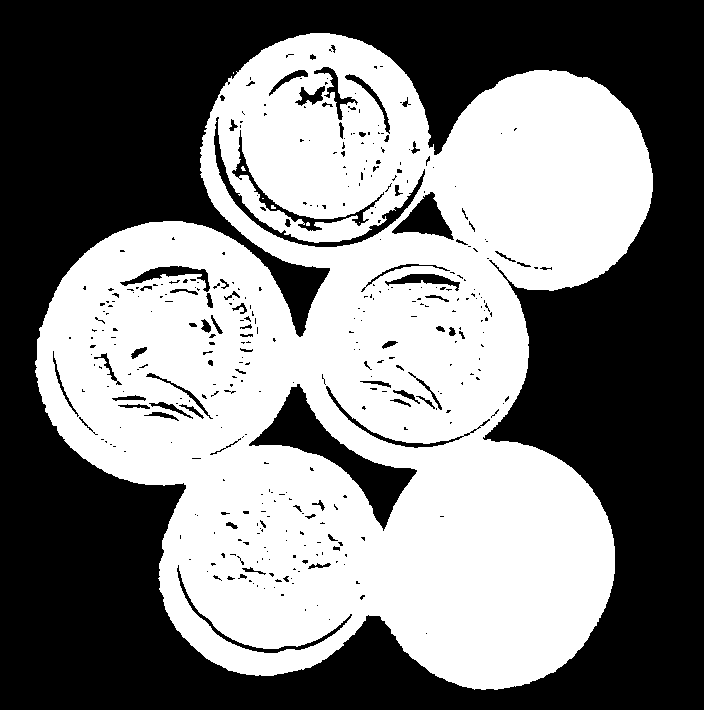

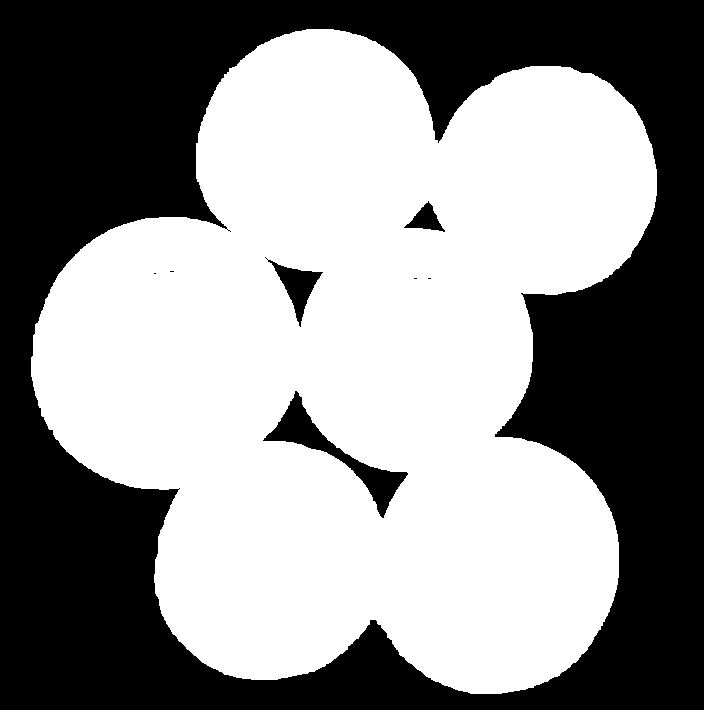

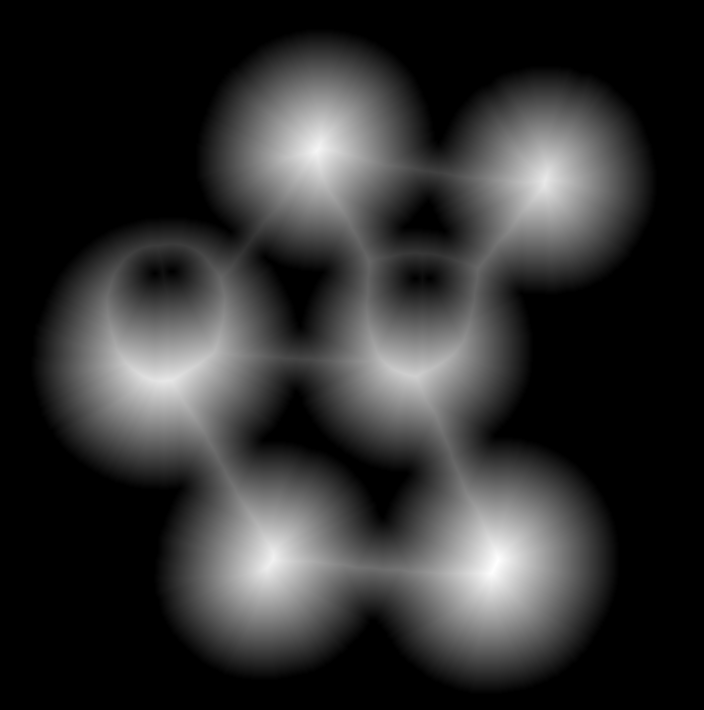

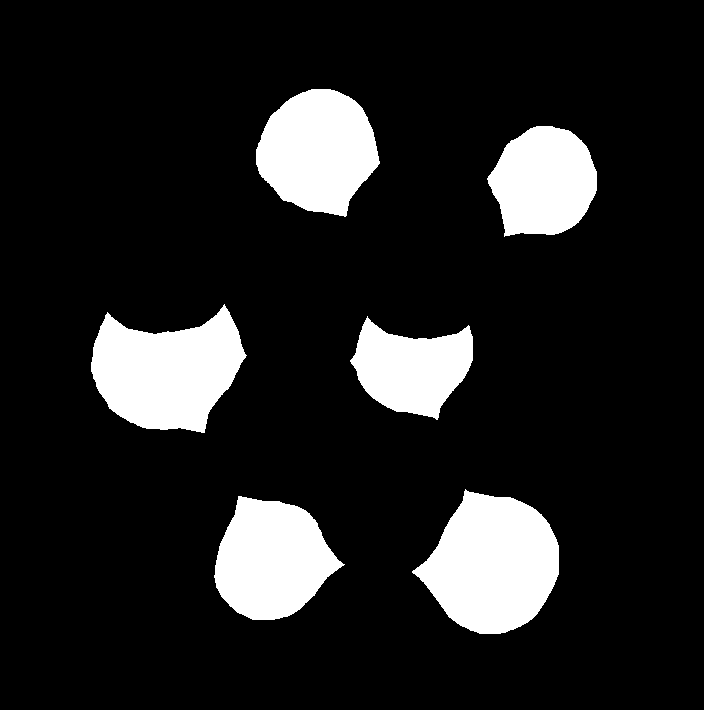

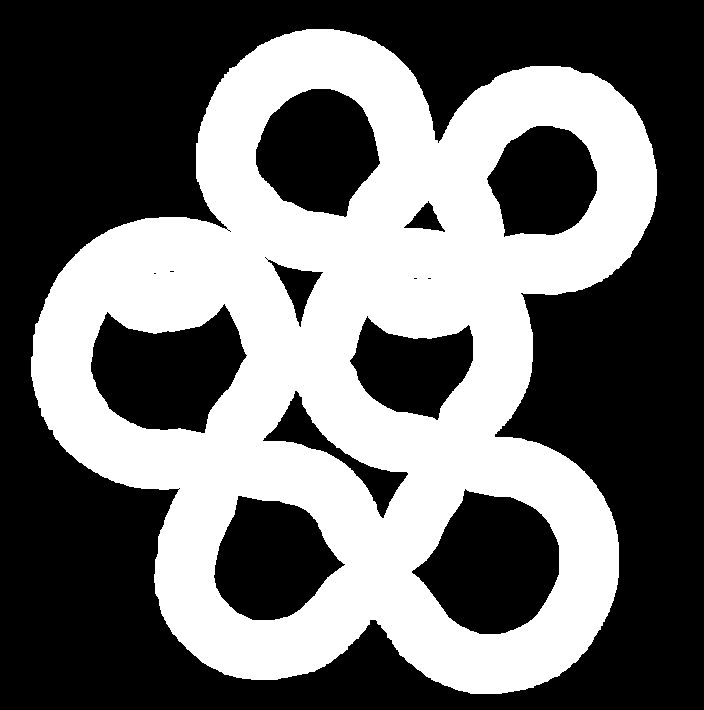

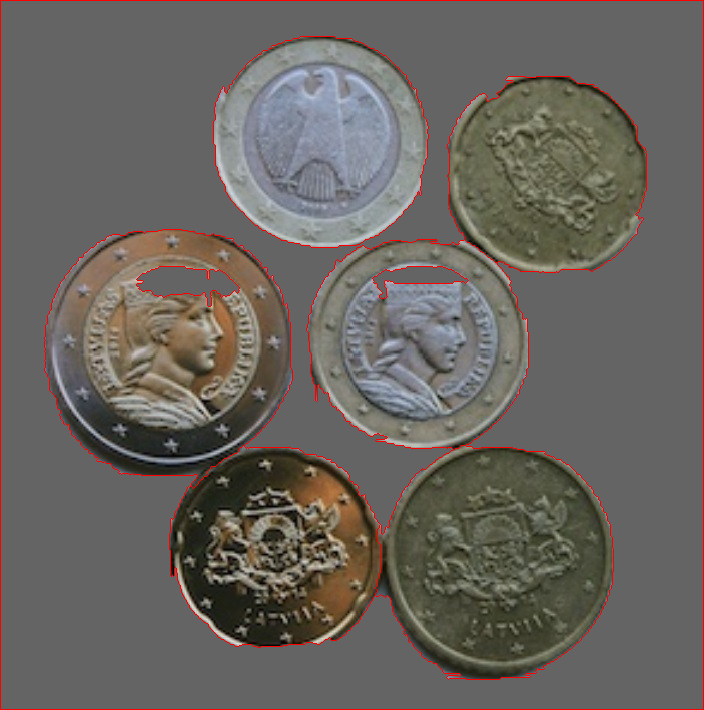

In [30]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/coins300x300.jpg')
cv2_imshow(img)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
ret, thresh = cv2.threshold(gray,160,255,cv2.THRESH_BINARY_INV)
cv2_imshow(thresh)


#모폴로지를 사용해 노이즈나 구멍제거
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (9,9))
sure_bg = cv2.dilate(thresh, kernel)
cv2_imshow(sure_bg)

#동전 중앙 부분을 검출하기 위해서 distance transform를 적용
dist_transform = cv2.distanceTransform(sure_bg, cv2.DIST_L2, 5)
result_dist_transform = cv2.normalize(dist_transform, None, 255, 0, cv2.NORM_MINMAX, cv2.CV_8UC1)
cv2_imshow(result_dist_transform)

# 이진화 스레시홀딩 적용
ret, sure_fg = cv2.threshold(dist_transform, 0.5*dist_transform.max(),255, cv2.THRESH_BINARY)
cv2_imshow(sure_fg)

sure_fg = np.uint8(sure_fg)
unknown = cv2.subtract(sure_bg,sure_fg)
cv2_imshow(unknown)

# 마커 라벨링
ret, markers = cv2.connectedComponents(sure_fg)

# 확실한 배경이 1이 되도록 모든 라벨에 1을 더함
markers = markers+1

# 확실하지 않은 구간을 0으로 처리
markers[unknown==255] = 0

markers = cv2.watershed(img, markers)

img[markers == -1] = [0, 0, 255]
img[markers == 1] = [100, 100, 100]

cv2_imshow(img)